# 04 · Quantum Visual Lab: see every step of quantum image processing

This notebook brings the QIP-Bench dashboard's visuals into Jupyter. Everything is computed live on Qiskit Aer.

| § | What you will see | Type |
|---|---|---|
| 1 | A qubit precessing on the Bloch sphere | animation · rotatable 3-D |
| 2 | An image being loaded into FRQI: circuit, pixel-by-pixel qubit states | circuit · animation · slider |
| 3 | **Wavefunction collapse**: the image rebuilt from real measurement shots | animation |
| 4 | FRQI vs NEQR vs QPIE, and baseline vs optimized circuits | table · charts |
| 5 | Factors in motion: noise cliff, shots, resolution, bit depth, operations | animations |
| 6 | Quantum Hadamard Edge Detection emerging from measurements | animation |
| 7 | Research results: which factors matter most | interactive Plotly |
| 8 | **Live control panel**: tune every factor and re-run | ipywidgets (needs a kernel) |

> Press ▶ under any animation to play it, or drag its slider. Plotly figures can be rotated, zoomed and hovered.
> Animations stay embedded in the saved notebook; the §8 panel needs *Run All*.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np
from IPython.display import display
from qipbench import viz, images
viz.setup()

## 1 · The qubit

A single qubit is $|\psi\rangle = \cos\frac{\theta}{2}|0\rangle + e^{i\varphi}\sin\frac{\theta}{2}|1\rangle$, a point on the Bloch sphere.
Below, the phase $\varphi$ advances (precession) while $\theta$ wobbles.

In [2]:
viz.bloch_precession()

The same sphere in 3-D. **Drag to rotate.** Here θ = π/2, φ = π/4: an equal superposition with a relative phase.

In [3]:
viz.bloch(np.pi / 2, np.pi / 4, 'Equal superposition with phase π/4')

## 2 · Loading an image into qubits (FRQI)

FRQI stores pixel $i$ as $\cos\theta_i|0\rangle + \sin\theta_i|1\rangle$ on **one colour qubit**, entangled with the
position register $|i\rangle$. The angle is $\theta_i = \frac{\pi}{2} I_i$.

### 2.1 The full pipeline on an 8×8 photo

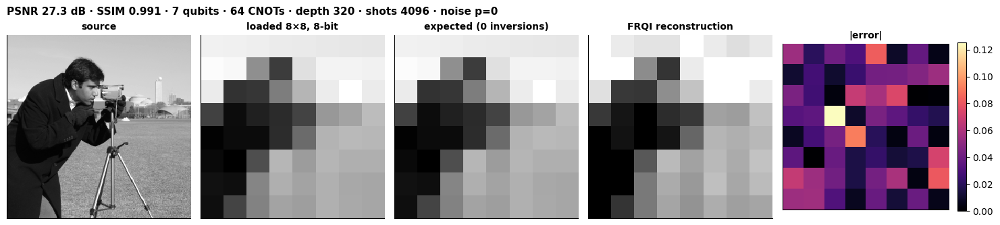

In [4]:
r8 = viz.run(encoding="frqi", image="camera", size=8, shots=4096)
viz.pipeline_strip(r8)

### 2.2 The circuit: baseline vs optimized structure (2×2 image)

Both circuits prepare **exactly the same state**. The optimized one uses a Gray-code uniformly controlled $R_Y$:
four CNOTs instead of a stack of multi-controlled rotations.

In [5]:
r2b = viz.run(encoding="frqi", image="camera", size=2, structure="baseline", shots=None)
r2o = viz.run(encoding="frqi", image="camera", size=2, structure="optimized", shots=None)
print("baseline:", r2b.metrics["cx"], "CNOTs after transpiling;  optimized:", r2o.metrics["cx"], "CNOTs")
viz.draw_circuit(r2o.circuit);

baseline: 24 CNOTs after transpiling;  optimized: 4 CNOTs


In [6]:
viz.draw_circuit(r2b.circuit, fold=40, scale=.55);

### 2.3 Every pixel is a qubit state: animated scan

Watch the highlighted pixel and its colour qubit. Bright pixels point toward $|1\rangle$ and dark ones toward $|0\rangle$.

In [7]:
r4 = viz.run(encoding="frqi", image="camera", size=4, shots=None)
viz.pixel_scan(r4)

Interactive version: **drag the slider** to pick a pixel and **rotate the sphere**.

In [8]:
viz.pixel_bloch(r8)

## 3 · Measurement: watching the wavefunction collapse

The image is never read out directly. Each shot collapses the register to one basis state $|c\rangle|i\rangle$.
These animations replay the **actual measured shots** (shuffled) and decode the image after each batch with the
same decoder as the pipeline. Blue cells have not been observed yet.

### 3.1 FRQI: quality is shot-limited

In [9]:
viz.shot_replay(r8)

### 3.2 NEQR: exact once every pixel is seen, even under noise

NEQR stores grey levels as basis states, so majority voting absorbs bit-flips. The run below uses noise p = 10⁻³.

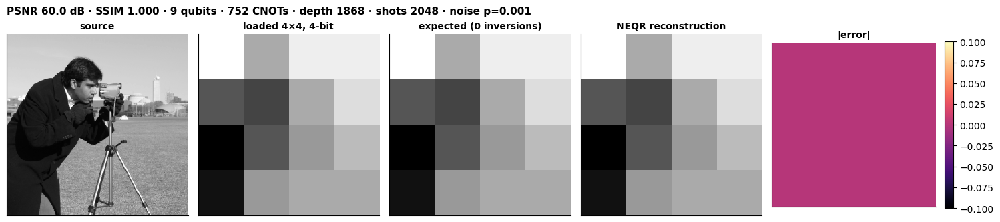

In [10]:
rn = viz.run(encoding="neqr", image="camera", size=4, bit_depth=4, noise=1e-3, shots=2048)
viz.pipeline_strip(rn)
viz.shot_replay(rn)

### 3.3 Amplitude encoding (QPIE): fewest qubits, sampling from |ψ|²

In [11]:
viz.shot_replay(viz.run(encoding='amplitude', image='phantom', size=8, shots=None))

## 4 · Comparing representations

### 4.1 Same image, three encodings

In [12]:
cmp = {e: viz.run(encoding=e, image="phantom", size=4, bit_depth=8, shots=4096) for e in ("frqi", "neqr", "amplitude")}
viz.metrics_table(cmp)

,qubits,cx,depth,psnr,ssim,level_accuracy,fidelity,coverage,total_s
frqi,5.0,16.0,64.0,33.9622,0.9965,0.3125,0.9980,1.00,0.0248
neqr,13.0,765.0,1846.0,60.0000,1.0000,1.0000,0.9990,1.00,0.2790
amplitude,4.0,11.0,37.0,36.0823,0.9984,0.2500,0.9992,0.75,0.0420


### 4.2 Circuit structure under noise: the biggest single lever

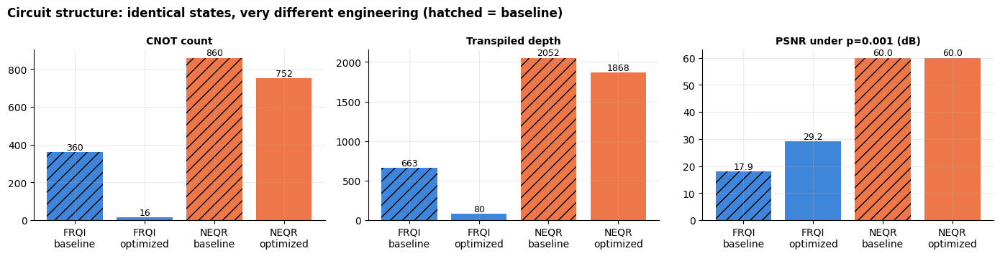

In [13]:
viz.structure_comparison(image='camera', size=4, noise=1e-3)

## 5 · Factors in motion

Each animation varies **one** factor and keeps the rest fixed, which is the controlled-experiment idea behind the study.

### 5.1 Noise: graceful (FRQI) vs threshold (NEQR)

In [14]:
viz.noise_sweep(image='camera', size=4, bit_depth=4)

### 5.2 Measurement shots (FRQI, 8×8)

In [15]:
viz.factor_sweep('shots', [32, 64, 128, 256, 512, 1024, 4096, 16384, 65536], encoding='frqi', size=8)

### 5.3 Image size: more detail, more qubits, fewer shots per pixel

In [16]:
viz.factor_sweep('size', [2, 4, 8, 16], encoding='frqi', image='camera', shots=4096)

### 5.4 Bit depth (NEQR: every extra bit is one more qubit)

In [17]:
viz.factor_sweep('bit_depth', [1, 2, 3, 4, 6, 8], encoding='neqr', image='camera', size=4, shots=4096)

### 5.5 Number of operations under noise (inversion stages)

In [18]:
viz.factor_sweep('operations', [0, 1, 2, 4, 8, 16], encoding='frqi', image='camera', size=4, noise=2e-3)

## 6 · Quantum Hadamard Edge Detection (QHED)

After $H\cdot D\cdot H$ on an ancilla, the odd basis states carry the neighbour differences $(c_i - c_{i+1})/2$.
Edges therefore emerge from measurement statistics. Weak edges need many shots because their probability scales
with the squared difference.

In [19]:
viz.qhed_animation(image='blocks', size=16)

In [20]:
viz.qhed_animation(image='phantom', size=16, threshold=.12)

## 7 · Research results: what really determines performance?

The figures below load `results/summary.json` (regenerate it with `python -m qipbench run`).
**Use the dropdowns** to switch encoding, dimension or study, and hover for effect sizes and p-values.

In [21]:
summary = viz.load_summary()
viz.factor_ranking(summary)

In [22]:
viz.ofat_explorer(summary, metric='psnr')

In [23]:
viz.ofat_explorer(summary, metric='cx')

## 8 · Live control panel

Pick any combination of factors and press **Run quantum pipeline**. The pipeline strip, shot replay and
circuit update live. *Needs a running kernel: widgets do not render in a static copy of this notebook.*

In [24]:
viz.lab()